# Compile single-cell FACS into minimal dataframe

This script compiles the raw FACS results from each well into one dataframe and writes it out as a compressed parquet file. 

In [36]:
from glob import glob
from os import stat
import pandas as pd
import numpy as np
import polars as pl
import os

In [37]:
dualipa_inputs = "../1_inputs"
dualipa_outputs = "../3_outputs"

n_cell_threshold = 800
wt_gfp_threshold = 100

## 1. Loading FACS data

In [38]:
# Download raw FACS data from Zenodo if haven't done so
# bash_file = f"{dualipa_inputs}/download_raw_FACS.sh"
# os.system(f"bash {bash_file}")

In [39]:
# Compile all data into single df
facs_data = f"{dualipa_inputs}/raw_inputs/FACS_single_cell_data_mCherry_positive_threshold_500/*"
all_df = []
for file_name in glob(facs_data):
    pla_id = file_name.split('/')[-1].split('_')[-3]
    well = file_name.split('/')[-1].split('_')[-2]
    if stat(file_name).st_size > 0:
        df = pd.read_csv(file_name,sep='\t',header=None).rename(columns={0:'GFP',1:'mCherry'})
        df['pla'] = int(pla_id)
        df['well'] = well
        df['n_cells'] = len(df)
        all_df.append(df)

pDEST_DUAL_df = pd.concat(all_df)
# Replace zeros with minimum non-zero value to avoid undefined after taking log
min_nonzero_val = pDEST_DUAL_df[pDEST_DUAL_df["GFP"] > 0]["GFP"].min()
pDEST_DUAL_df.loc[pDEST_DUAL_df["GFP"] == 0, "GFP"] = min_nonzero_val

pDEST_DUAL_df = pl.DataFrame(pDEST_DUAL_df)

In [40]:
# Get GFP:mCherry ratio after replacing zeros with min-value
pDEST_DUAL_df = pDEST_DUAL_df.with_columns(
    (pl.col("GFP") / pl.col("mCherry")).alias("GFP_mCherry_ratio")
)

In [41]:
# Calculate means and medians while grouping by plate and well
agg_df = pDEST_DUAL_df.group_by(["pla", "well"]).agg(
    pl.col("GFP").mean().alias('avg_gfp'),
    pl.col("mCherry").mean().alias("avg_mcherry"),
    pl.col("GFP").median().alias("median_gfp"),
    pl.col("mCherry").median().alias("median_mcherry"),
    pl.col("GFP_mCherry_ratio").mean().alias("avg_GFP_mCherry_ratio"),
    pl.col("GFP_mCherry_ratio").median().alias("median_GFP_mCherry_ratio")
)
pDEST_DUAL_df = pDEST_DUAL_df.join(agg_df, on=["pla", "well"])#.to_pandas()

In [42]:
pDEST_DUAL_df

GFP,mCherry,pla,well,n_cells,GFP_mCherry_ratio,avg_gfp,avg_mcherry,median_gfp,median_mcherry,avg_GFP_mCherry_ratio,median_GFP_mCherry_ratio
f64,f64,i64,str,i64,f64,f64,f64,f64,f64,f64,f64
8.190001,609.700012,3,"""C09""",9149,0.013433,41.933584,4860.99931,32.760002,3332.0,0.016161,0.008973
42.77,5862.5,3,"""C09""",9149,0.007296,41.933584,4860.99931,32.760002,3332.0,0.016161,0.008973
54.600002,2845.5,3,"""C09""",9149,0.019188,41.933584,4860.99931,32.760002,3332.0,0.016161,0.008973
27.300001,6203.399902,3,"""C09""",9149,0.004401,41.933584,4860.99931,32.760002,3332.0,0.016161,0.008973
49.140003,7377.299805,3,"""C09""",9149,0.006661,41.933584,4860.99931,32.760002,3332.0,0.016161,0.008973
…,…,…,…,…,…,…,…,…,…,…,…
747.960022,1572.900024,12,"""A10""",8933,0.475529,2397.877414,5726.17151,1781.119995,4270.699707,0.76086,0.447973
8532.080078,11872.0,12,"""A10""",8933,0.718673,2397.877414,5726.17151,1781.119995,4270.699707,0.76086,0.447973
4703.959961,2354.800049,12,"""A10""",8933,1.997605,2397.877414,5726.17151,1781.119995,4270.699707,0.76086,0.447973


## 2. Merge with meta mutation data

In [43]:
# Merge with minimal metadata
pdest_layout_df = pl.read_csv(f"{dualipa_outputs}/dualipa_experimental_layout.csv")
pDEST_DUAL_df = pDEST_DUAL_df.join(pdest_layout_df, 
                                   left_on=['pla','well'], 
                                   right_on=['dest_pla_id','dest_well'], 
                                   suffix="_sc"
)
pDEST_DUAL_df = pDEST_DUAL_df.with_columns(
    pl.concat_str([pl.col("pla").cast(pl.String), pl.col("well").cast(pl.String)], separator="_").alias("coordinates"),
    ## filtering scheme with no sequence confirmation, DEPRECATED. 
    ## kept for reference just in case.
    # pl.when(
    #     ((pl.col("n_cells") >= n_cell_threshold) & (pl.col("mut_id") > 0))
    #     | ((pl.col("mut_id") == 0) & (pl.col("avg_gfp") >= wt_gfp_threshold))
    # )
    # .then(pl.lit(True))
    # .otherwise(pl.lit(False))
    # .alias("valid_well_no_seq_conf")
)

In [44]:
# pDEST_DUAL_df.unique("orf_id").group_by("dualip_ref_sequence_confirmation_class").agg(pl.len())#ount()#.unique()

In [45]:
## define valid wells
# Convert columns to integer (NULL -> None)
columns_to_cast = [
    "entry_sequence_confirmation_class",
    "dualip_sequence_confirmation_class",
    "dualip_ref_sequence_confirmation_class",
]
pDEST_DUAL_seq_confirm_df = pDEST_DUAL_df.with_columns([
    pl.col(col).cast(pl.Float64, strict=False) for col in columns_to_cast
])

## Define masks for variant allele filtering
# At least one entry sequence vector is good
any_expression_good = (
    pl.col("entry_sequence_confirmation_class").is_in([1, 2])
)
mutant_mask = (pl.col('n_cells') >= n_cell_threshold) & (pl.col('mut_id') > 0)
entry_good = pl.col("dualip_sequence_confirmation_class").is_in([1, 2])
# entry_discard = pl.col("dualip_sequence_confirmation_class").is_in([3, 4, 5, 6])
entry_null_like = pl.col("dualip_sequence_confirmation_class").is_in([7, 99]) | pl.col("dualip_sequence_confirmation_class").is_null()
mutant_mask_all = mutant_mask & (entry_good | (entry_null_like & any_expression_good))

## Define masks for reference allele filtering
wt_mask = (pl.col('mut_id') == 0) & (pl.col('avg_gfp') >= wt_gfp_threshold)
## Define masks for allele filtering IS NOT applicable for WT
# entry_ref_good = pl.col("dualip_ref_sequence_confirmation_class").is_in([1, 2])
# entry_ref_null_like = pl.col("dualip_ref_sequence_confirmation_class").is_in([7, 99]) | pl.col("dualip_ref_sequence_confirmation_class").is_null()
# wt_mask_all = wt_mask & (entry_ref_good | (entry_ref_null_like & any_expression_good))

## Combine logic
pDEST_DUAL_seq_confirm_df = pDEST_DUAL_seq_confirm_df.with_columns(
    pl.when(mutant_mask_all | wt_mask)
    .then(True)
    .otherwise(False)
    .alias("valid_well")
)

## filter the valid wells ONLY
pDEST_DUAL_seq_confirm_df = pDEST_DUAL_seq_confirm_df.filter(pl.col("valid_well"))

In [64]:
orf_id_symbol_mapping = dict(zip(
    pDEST_DUAL_seq_confirm_df.filter(pl.col("symbol").is_not_null())["orf_id"].to_list(),
    pDEST_DUAL_seq_confirm_df.filter(pl.col("symbol").is_not_null())["symbol"].to_list()
))
# orf_id_symbol_mapping

In [70]:
orf_id_symbol_mapping[55855]

'KRT2'

## 3. WT Reproducibility

In [55]:
pDEST_DUAL_seq_confirm_wt_df

orf_id,mut_id,pla,well,gene_variant,Avg_GFP_mCherry_ratio_Mean
i64,i64,i64,str,str,f64
10735,0,15,"""F11""",null,1.043851
55855,0,3,"""G09""",null,0.467749
4723,0,10,"""B01""",null,0.62201
2920,0,26,"""C07""",null,1.542081
7662,0,5,"""E11""",null,0.992207
…,…,…,…,…,…
12043,0,13,"""B12""",null,0.103003
8409,0,6,"""C08""",null,0.568343
5442,0,6,"""D09""",null,0.754414


In [82]:
pDEST_DUAL_seq_confirm_wt_df = pDEST_DUAL_seq_confirm_df.filter(pl.col("mut_id")==0)
pDEST_DUAL_seq_confirm_wt_df = pDEST_DUAL_seq_confirm_wt_df.group_by(
    ["orf_id", "mut_id", "pla", "well"]
).agg(
    pl.col("avg_GFP_mCherry_ratio").mean().alias("Avg_GFP_mCherry_ratio_Mean")
)
pDEST_DUAL_seq_confirm_wt_df = pDEST_DUAL_seq_confirm_wt_df.with_columns(
    pl.col("orf_id").map_elements(lambda x: orf_id_symbol_mapping[x] if x in orf_id_symbol_mapping else pl.Null, return_dtype=pl.String).alias("symbol")
)
pDEST_DUAL_seq_confirm_wt_df

orf_id,mut_id,pla,well,Avg_GFP_mCherry_ratio_Mean,symbol
i64,i64,i64,str,f64,str
3643,0,9,"""C03""",0.263622,"""EIF2B4"""
3643,0,9,"""D03""",0.304894,"""EIF2B4"""
54914,0,5,"""B12""",0.639131,"""TAT"""
3438,0,18,"""A10""",0.055213,"""TMEM43"""
4692,0,6,"""C07""",2.014752,"""LDHB"""
…,…,…,…,…,…
8409,0,6,"""F08""",0.61494,"""PDGFRB"""
5442,0,6,"""D09""",0.754414,"""SIX1"""
8420,0,4,"""E08""",0.212462,"""ALAS2"""


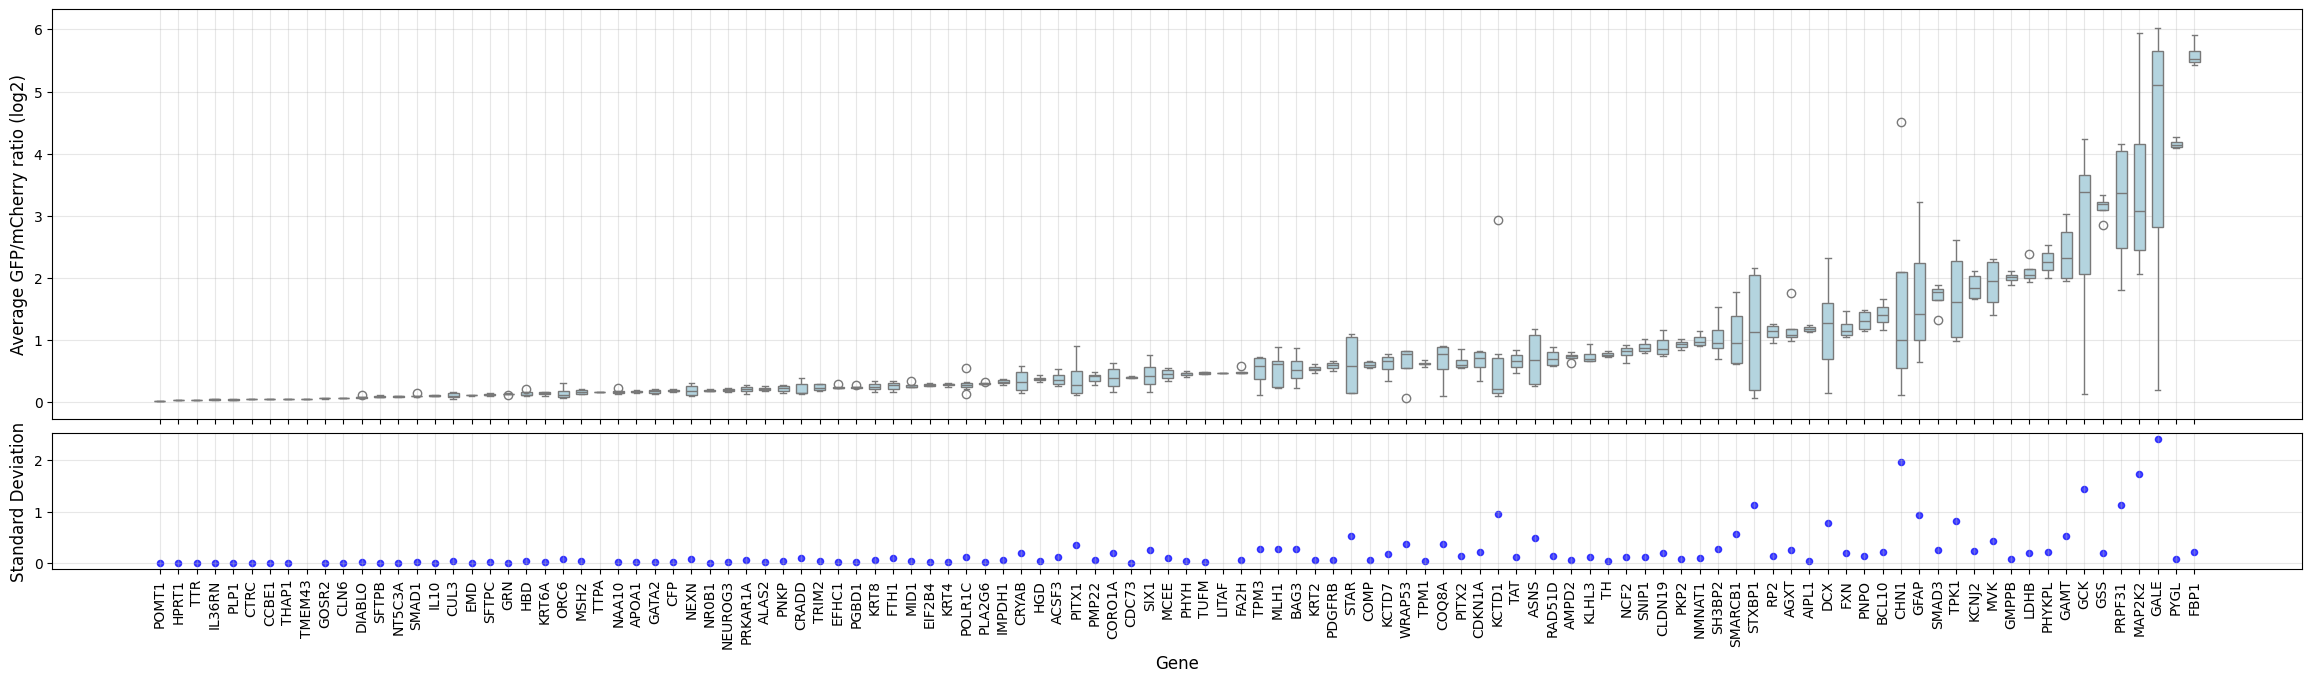

In [100]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

df = pDEST_DUAL_seq_confirm_wt_df.to_pandas()
gene_col, value_col, std_col = "symbol", "Avg_GFP_mCherry_ratio_Mean", "STD"

# Calculate gene order
gene_means = df.groupby(gene_col)[value_col].mean().sort_values()
ordered_genes = gene_means.index.tolist()

# Create figure with two subplots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(25,7), sharex=True, 
                               gridspec_kw={'height_ratios': [3, 1], 'hspace': 0.05})

# Top panel: Boxplots with seaborn
sns.boxplot(data=df, x=gene_col, y=value_col, order=ordered_genes, 
            ax=ax1, color='lightblue', width=0.6)
ax1.set_ylabel('Average GFP/mCherry ratio (log2)', fontsize=12)
ax1.set_xlabel('')
ax1.grid(True, alpha=0.3)
# ax1.set_ylim(-6, 3)

# Bottom panel: Standard deviation
if std_col not in df.columns:
    gene_stds = df.groupby(gene_col)[value_col].std().reindex(ordered_genes)
else:
    gene_stds = df.groupby(gene_col)[std_col].first().reindex(ordered_genes)

ax2.scatter(range(len(ordered_genes)), gene_stds.values, 
            s=20, alpha=0.7, color='blue')
ax2.set_ylabel('Standard Deviation', fontsize=12)
ax2.set_xlabel('Gene', fontsize=12)
ax2.grid(True, alpha=0.3)
# ax2.set_ylim(-0.1, 2)

# Set x-axis labels
# step = max(1, len(ordered_genes) // 20)
ax2.set_xticks(range(len(ordered_genes)))
gene_x_labels = ax2.set_xticklabels([ordered_genes[i] for i in range(0, len(ordered_genes))], 
                    rotation=90, fontsize=10)

# Remove x-axis labels from top panel
# ax1.set_xticklabels([])

plt.subplots_adjust(left=0.05, right=0.95, top=0.95, bottom=0.15, hspace=0.05)

In [30]:
# pDEST_DUAL_seq_confirm_df.filter((pl.col("orf_id")==3438)&(pl.col("mut_id")==0)&(pl.col("pla")==18)).unique("well")
# pdest_layout_df.filter((pl.col("dest_pla_id")==18)&(pl.col("dest_well")=="E11"))
# pDEST_DUAL_seq_confirm_df.filter((pl.col("pla")==18)&(pl.col("well")=="E11"))
# .group_by(
#     "well"
# ).agg(
#     pl.col("avg_gfp").mean().alias("avg_gfp_well")

In [12]:
# write out single-cell data
pDEST_DUAL_seq_confirm_df.write_parquet(f"{dualipa_outputs}/facs_single_cell.parquet", compression="zstd")